In [99]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import pandas as pd
import matplotlib.pyplot as plt

In [100]:
df=pd.read_csv("Exp-1.csv")
df

,Input,Output
0,1,2
1,2,4
2,3,6
3,4,8
4,5,10
5,6,12
6,7,14
7,8,16
8,9,18
9,10,20


In [101]:
x=df[["Input"]].values
y=df[["Output"]].values

In [102]:
xt,xst,yt,yst=train_test_split(x,y,test_size=0.40,random_state=42)

In [103]:
scaler1=MinMaxScaler()
scaler2=MinMaxScaler()
xt=scaler1.fit_transform(xt)
xst=scaler2.fit_transform(xst)

In [104]:
xt1=torch.FloatTensor(xt)
xst1=torch.FloatTensor(xst)
yt1=torch.FloatTensor(yt)
yst1=torch.FloatTensor(yst)

In [105]:
class neuralnet(nn.Module):
    def __init__(self):
        super().__init__()
        self.network=nn.Sequential(
          nn.Linear(1,20),
          nn.ReLU(),
          nn.Linear(20,10),
          nn.ReLU(),
          nn.Linear(10,1)
        )
    def forward(self,x):
        return self.network(x)

In [106]:
model=neuralnet()
criterion=nn.MSELoss()
optimizer=optim.Adam(model.parameters(),lr=0.01)

In [107]:
epochs=1000
for i in range(epochs):
    optimizer.zero_grad()
    pred=model(xt1)
    loss=criterion(pred,yt1)
    loss.backward()
    optimizer.step()
    if i%100==0:
        print(f"Epochs:{i} Loss:",loss.item())

Epochs:0 Loss: 296.4930419921875
Epochs:100 Loss: 11.383075714111328
Epochs:200 Loss: 0.14577053487300873
Epochs:300 Loss: 0.020440636202692986
Epochs:400 Loss: 0.006464467383921146
Epochs:500 Loss: 0.0016862018965184689
Epochs:600 Loss: 0.0003629586426541209
Epochs:700 Loss: 8.924721623770893e-05
Epochs:800 Loss: 3.788202957366593e-05
Epochs:900 Loss: 1.490595968789421e-05


with torch.no_grad():
    pred=model(xst)
    loss=criterion(pred,yst)
    print(loss.item())

In [108]:
with torch.no_grad():
    pred=model(xst1)
    loss=criterion(pred,yst1)
    print(loss.item())

4.004246234893799


In [109]:
input=torch.FloatTensor(scaler1.transform([[16]]))
pred=model(input)
print(pred.item())

32.00128173828125


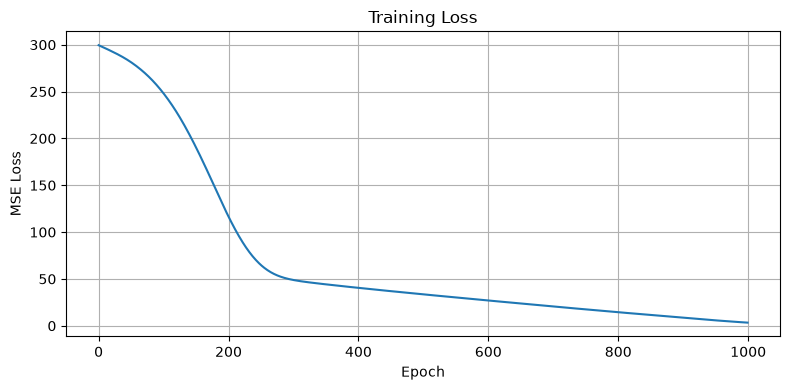

In [110]:
torch.manual_seed(33)
plot_model = neuralnet()
plot_optimizer = optim.Adam(plot_model.parameters(), lr=0.001)
loss_list = []

for epoch in range(1000):
    plot_optimizer.zero_grad()
    outputs = plot_model(xt1)
    plot_loss = criterion(outputs, yt1)
    plot_loss.backward()
    plot_optimizer.step()
    loss_list.append(plot_loss.item())

plt.figure(figsize=(8, 4))
plt.plot(loss_list)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Loss")
plt.grid(True)
plt.tight_layout()
plt.show()